# XAI benchmark analysis: environmental contribution across seeds

This notebook uses only the attributions already produced by `tester.py` and aggregated by `run_benchmark.py`:

- `benchmark_results/<configuration>/attributions_species_all.parquet`
- `benchmark_results/<configuration>/attributions_spatial_all.parquet`

Objective: determine whether the environmental branch of the **Environment + phylogeny** model remains informative and interpretable even when the average predictive gain is small.

## Statistical rule

The **seed is the unit of replication**. For each feature/target, values are first aggregated across species within each seed; the mean and 95% CI are then calculated across seeds. Configuration comparisons use paired differences between matching seeds.

## Limitations of the current artifacts

- In `tester.py`, `Phylo` is stored as the mean `|IG|` across the phylogenetic embedding dimensions, so the phylogenetic sign is no longer available.
- Species-side and spatial-side IG values are calculated in separate calls. Normalized shares are therefore calculated within their respective branches, not as an exact global decomposition of the prediction.

In [1]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display

pd.set_option('display.max_columns', 200)
pd.set_option('display.width', 160)
pd.set_option('display.max_rows', 100)

In [21]:
PROJECT_ROOT = Path.cwd().parent.resolve()
RESULTS_DIR = PROJECT_ROOT / 'benchmark_results'
OUTPUT_DIR = PROJECT_ROOT / 'xai_benchmark_analysis'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

CONFIDENCE = 0.95
TOP_N_FEATURES = 20
TOP_K_OVERLAP = 10
TOP_N_SPECIES = 30
FEATURE_CACHE_VERSION = 2

CONFIG_MAP = {
    'no_env_no_phylo': 'baseline',
    'env_only': 'environment',
    'phylo_only': 'phylogeny',
    'env_phylo': 'full',
}
CONFIG_LABELS = {
    'baseline': 'No additional inputs',
    'environment': 'Environment only',
    'phylogeny': 'Phylogeny only',
    'full': 'Environment + phylogeny',
}

FEATURE_LABELS = {
  "wc2.1_2.5m_bio_1_1": "Annual mean temperature",
  "wc2.1_2.5m_bio_12_1": "Annual precipitation",
  "wc2.1_2.5m_bio_7_1": "Temperature annual range",
  "wc2.1_2.5m_bio_2_1": "Mean diurnal temperature range",
  "NZ population density layer_1": "Population density",
  "wc2.1_2.5m_bio_15_1": "Precipitation seasonality",

  "wc2.1_2.5m_srad_01_1": "Solar radiation - January",
  "wc2.1_2.5m_srad_02_1": "Solar radiation - February",
  "wc2.1_2.5m_srad_03_1": "Solar radiation - March",
  "wc2.1_2.5m_srad_04_1": "Solar radiation - April",
  "wc2.1_2.5m_srad_05_1": "Solar radiation - May",
  "wc2.1_2.5m_srad_06_1": "Solar radiation - June",
  "wc2.1_2.5m_srad_07_1": "Solar radiation - July",
  "wc2.1_2.5m_srad_08_1": "Solar radiation - August",
  "wc2.1_2.5m_srad_09_1": "Solar radiation - September",
  "wc2.1_2.5m_srad_10_1": "Solar radiation - October",
  "wc2.1_2.5m_srad_11_1": "Solar radiation - November",
  "wc2.1_2.5m_srad_12_1": "Solar radiation - December",

  "wc2.1_2.5m_vapr_01_1": "Water vapour pressure - January",
  "wc2.1_2.5m_vapr_02_1": "Water vapour pressure - February",
  "wc2.1_2.5m_vapr_03_1": "Water vapour pressure - March",
  "wc2.1_2.5m_vapr_04_1": "Water vapour pressure - April",
  "wc2.1_2.5m_vapr_05_1": "Water vapour pressure - May",
  "wc2.1_2.5m_vapr_06_1": "Water vapour pressure - June",
  "wc2.1_2.5m_vapr_07_1": "Water vapour pressure - July",
  "wc2.1_2.5m_vapr_08_1": "Water vapour pressure - August",
  "wc2.1_2.5m_vapr_09_1": "Water vapour pressure - September",
  "wc2.1_2.5m_vapr_10_1": "Water vapour pressure - October",
  "wc2.1_2.5m_vapr_11_1": "Water vapour pressure - November",
  "wc2.1_2.5m_vapr_12_1": "Water vapour pressure - December",

  "calciumraster_1": "Exchangeable soil calcium",
  "drainageraster_1": "Soil drainage capacity",
  "ecoraster_1": "Ecological raster 1",
  "ecoraster_2": "Ecological raster 2",
  "hardnessraster_1": "Soil induration (hardness)",
  "limiation_to_growthraster_1": "Chemical limitations to plant growth",
  "pHraster_1": "Soil pH",
  "particle_sizeraster_1": "Soil particle size",
  "phosphorousraster_1": "Acid-soluble soil phosphorus",
  "soil_ageraster_1": "Soil age",

  "wc2.1_2.5m_elev_1": "Elevation above sea level",

  "pos_0": "Position encoding 0",
  "pos_1": "Position encoding 1",
  "pos_2": "Position encoding 2",
  "pos_3": "Position encoding 3"
}

pretty_trait_map = {
    "Alt": "Altitude range",
    "Spore": "Spore size",
    "FertileFrond": "Fertile frond length",
    "SterileFrond": "Sterile frond length",
    "Ferstipe": "Fertile stipe length",
    "SterileStipe": "Sterile stipe length",
}

TARGET_ORDER = [ 
    'Alt',
    'Ferstipe',
    'SterileStipe',
    'FertileFrond',
    'SterileFrond',
    'Spore',
    ]

print('PROJECT_ROOT:', PROJECT_ROOT)
print('RESULTS_DIR:', RESULTS_DIR)
print('OUTPUT_DIR:', OUTPUT_DIR)

PROJECT_ROOT: /home/smonaco/newzeland-plants
RESULTS_DIR: /home/smonaco/newzeland-plants/benchmark_results
OUTPUT_DIR: /home/smonaco/newzeland-plants/xai_benchmark_analysis


## Seed-aware statistical utilities

In [3]:
def mean_ci(values, confidence=CONFIDENCE):
    x = pd.Series(values, dtype=float).dropna().to_numpy()
    n = len(x)
    if n == 0:
        return {'mean':np.nan,'sd':np.nan,'sem':np.nan,'ci_low':np.nan,'ci_high':np.nan,'n_seeds':0}
    m = float(np.mean(x))
    if n == 1:
        return {'mean':m,'sd':0.0,'sem':np.nan,'ci_low':np.nan,'ci_high':np.nan,'n_seeds':1}
    sd = float(np.std(x, ddof=1))
    sem = sd / np.sqrt(n)
    q = stats.t.ppf((1 + confidence) / 2, df=n - 1)
    return {'mean':m,'sd':sd,'sem':sem,'ci_low':m-q*sem,'ci_high':m+q*sem,'n_seeds':n}


def summarise_seed_values(frame, value, by):
    rows = []
    for key, g in frame.groupby(by, dropna=False, sort=False):
        if not isinstance(key, tuple):
            key = (key,)
        row = dict(zip(by, key))
        row.update(mean_ci(g[value]))
        rows.append(row)
    return pd.DataFrame(rows)


def paired_seed_difference(frame, value, config_a, config_b, pair_cols, config_col='configuration_id'):
    a = frame.loc[frame[config_col].eq(config_a), pair_cols + ['seed', value]].rename(columns={value:'value_a'})
    b = frame.loc[frame[config_col].eq(config_b), pair_cols + ['seed', value]].rename(columns={value:'value_b'})
    p = a.merge(b, on=pair_cols + ['seed'], how='inner', validate='one_to_one')
    p['delta'] = p['value_a'] - p['value_b']
    return p


def horizontal_ci_plot(table, label_col, title, xlabel):
    if table.empty:
        return
    p = table.sort_values('mean').reset_index(drop=True)
    y = np.arange(len(p))
    x = p['mean'].to_numpy(float)
    xerr = np.vstack([x-p['ci_low'].to_numpy(float), p['ci_high'].to_numpy(float)-x])
    fig, ax = plt.subplots(figsize=(9, max(4.5, 0.32*len(p))))
    ax.errorbar(x, y, xerr=xerr, fmt='o', capsize=3)
    ax.set_yticks(y)
    ax.set_yticklabels(p[label_col].astype(str))
    ax.set_xlabel(xlabel)
    ax.set_title(title)
    ax.grid(axis='x', alpha=0.2)
    plt.tight_layout()
    plt.show()

In [4]:
ID_COLUMNS = {
    'seed','model','source','species','target_trait','variable',
    'use_env_features','use_phylo_features','configuration_id','configuration',
    'experiment_dir','attribution_protocol'
}

def load_attribution_files(results_dir, kind):
    frames = []
    for folder, config_id in CONFIG_MAP.items():
        path = results_dir / folder / f'attributions_{kind}_all.parquet'
        if not path.exists():
            continue
        f = pd.read_parquet(path).copy()
        f['configuration_id'] = config_id
        f['configuration'] = CONFIG_LABELS[config_id]
        f['experiment_dir'] = folder
        frames.append(f)
    if not frames:
        return pd.DataFrame()
    out = pd.concat(frames, ignore_index=True, sort=False)
    out['seed'] = pd.to_numeric(out['seed'], errors='coerce')
    return out

species_raw = load_attribution_files(RESULTS_DIR, 'species')
spatial_raw = load_attribution_files(RESULTS_DIR, 'spatial')
print('species rows:', len(species_raw))
print('spatial rows:', len(spatial_raw))

species rows: 979200
spatial rows: 489600


In [5]:
def seed_inventory(frame, kind):
    if frame.empty:
        return pd.DataFrame()
    rows=[]
    for config_id, g in frame.groupby('configuration_id'):
        seeds=sorted(g['seed'].dropna().astype(int).unique().tolist())
        rows.append({
            'kind':kind,'configuration_id':config_id,'configuration':CONFIG_LABELS.get(config_id,config_id),
            'n_rows':len(g),'n_seeds':len(seeds),'min_seed':min(seeds) if seeds else np.nan,
            'max_seed':max(seeds) if seeds else np.nan,'seeds':seeds
        })
    return pd.DataFrame(rows)

inventory = pd.concat([seed_inventory(species_raw,'species'), seed_inventory(spatial_raw,'spatial')], ignore_index=True)
display(inventory.drop(columns=['seeds'], errors='ignore'))

for kind, sub in inventory.groupby('kind') if not inventory.empty else []:
    sets=[set(x) for x in sub['seeds']]
    common=sorted(set.intersection(*sets)) if sets else []
    union=sorted(set.union(*sets)) if sets else []
    print(f'{kind}: {len(common)} common seeds / {len(union)} total seeds')
    for _, row in sub.iterrows():
        miss=sorted(set(union)-set(row['seeds']))
        if miss:
            print(' ', row['configuration_id'], 'missing:', miss)

,kind,configuration_id,configuration,n_rows,n_seeds,min_seed,max_seed
0,species,baseline,No additional inputs,244800,60,40,139
1,species,environment,Environment only,244800,60,40,139
2,species,full,Environment + phylogeny,244800,60,40,139
3,species,phylogeny,Phylogeny only,244800,60,40,139
4,spatial,environment,Environment only,244800,60,40,139
5,spatial,full,Environment + phylogeny,244800,60,40,139


spatial: 60 common seeds / 60 total seeds
species: 60 common seeds / 60 total seeds


## Reconstructing environmental names and long format

If the CSV caches in `data/Ferns/Complete layers` are available, the `env_<n>` columns are mapped back to their original names. Replicates of the same feature are collapsed by species/seed before averaging.

In [6]:
def environment_source_columns(project_root):
    d=project_root/'data'/'Ferns'/'Complete layers'
    paths=[
        d/f'Climatic layers_space_df_v{FEATURE_CACHE_VERSION}.csv',
        d/f'population density and elevation layer_space_df_v{FEATURE_CACHE_VERSION}.csv',
        d/f'Soil NZ layers_space_df_v{FEATURE_CACHE_VERSION}.csv',
    ]
    if all(p.exists() for p in paths):
        return [c for p in paths for c in pd.read_csv(p,index_col=0).columns.astype(str).tolist()]
    return []

def environment_domain(feature):
    f=str(feature).lower()
    if any(t in f for t in ['bio','temperatur','precipit','solar', 'srad','radiaz','vapore','vapor','vapr','clim']): return 'Climate'
    if any(t in f for t in ['soil','suolo','ph','carbon','nitrogen','clay','sand','silt']): return 'Soil'
    if any(t in f for t in ['elev','altitud','dem']): return 'Elevation'
    if any(t in f for t in ['population']): return 'Density'
    if any(t in f for t in ['pos']): return 'Position'
    return 'Soil'

def build_env_metadata(frame):
    if frame.empty:
        return {}
    env_cols=sorted([c for c in frame.columns if c in FEATURE_LABELS])
    src=environment_source_columns(PROJECT_ROOT)
    mapping={}
    if src and len(env_cols)%len(src)==0:
        for i,c in enumerate(env_cols):
            print('foo')
            s=src[i%len(src)]
            mapping[c]={'source':s,'canonical':FEATURE_LABELS.get(s,''),'replica':i//len(src)+1, 'domain':environment_domain(s)}
    else:
        for c in env_cols:
            mapping[c]={'source':c,'canonical':FEATURE_LABELS.get(c,''),'replica':1, 'domain':environment_domain(c)}
    return mapping

ENV_METADATA=build_env_metadata(spatial_raw)
print('mapped environmental features:', len(ENV_METADATA))
display(pd.DataFrame(ENV_METADATA).T.domain.value_counts())

mapped environmental features: 45


domain
Climate      29
Soil         10
Position      4
Density       1
Elevation     1
Name: count, dtype: int64

In [7]:
env_df = pd.DataFrame(ENV_METADATA).T.reset_index(drop=True).drop(columns=['replica', 'source'])
env_df = env_df.sort_values(by='domain').rename(columns={'domain':'Domain','canonical':'Environmental feature'}).reset_index(drop=True)
env_df#.to_latex()


,Environmental feature,Domain
0,Solar radiation - February,Climate
1,Solar radiation - April,Climate
2,Solar radiation - May,Climate
3,Solar radiation - June,Climate
4,Solar radiation - July,Climate
5,Solar radiation - August,Climate
6,Solar radiation - September,Climate
7,Solar radiation - October,Climate
8,Solar radiation - November,Climate
9,Solar radiation - December,Climate


In [8]:
def species_descriptor(feature):
    m=re.fullmatch(r'(min|max|range)_(.+)', feature)
    if m:
        return 'Observed traits', f'{m.group(2)} ({m.group(1)})', True
    if feature.startswith('gen_'):
        return 'Genetics and categories', feature.removeprefix('gen_').replace('_',': ',1), True
    if feature.lower()=='phylo' or feature.startswith('phylo_'):
        return 'Phylogeny', 'Phylogenetic embedding', False
    return 'Other species inputs', feature.replace('_',' '), True


def spatial_descriptor(feature):
    if feature.startswith('pos_'):
        return 'Position', f'Position encoding {int(feature.split("_")[1])+1}', feature
    meta=ENV_METADATA.get(feature)
    if meta:
        return 'Environment', meta['canonical'], meta['source']
    return 'Environment', FEATURE_LABELS.get(feature, 'Unknown'), feature


def to_species_long(frame):
    if frame.empty:
        return pd.DataFrame()
    ids=[c for c in ID_COLUMNS if c in frame.columns]
    feats=[c for c in frame.columns if c not in ids and pd.api.types.is_numeric_dtype(frame[c])]
    x=frame[ids+feats].melt(id_vars=ids,value_vars=feats,var_name='raw_feature',value_name='signed_ig')
    desc=[species_descriptor(str(v)) for v in x['raw_feature']]
    x['input_group']=[v[0] for v in desc]
    x['feature']=[v[1] for v in desc]
    x['signed_available']=[v[2] for v in desc]
    x['signed_ig']=pd.to_numeric(x['signed_ig'],errors='coerce').fillna(0.0)
    x['absolute_ig']=np.where(x['signed_available'],x['signed_ig'].abs(),x['signed_ig'].clip(lower=0))
    return x


def to_spatial_long(frame):
    if frame.empty:
        return pd.DataFrame()
    ids=[c for c in ID_COLUMNS if c in frame.columns]
    feats=[c for c in frame.columns if c not in ids and pd.api.types.is_numeric_dtype(frame[c])]
    x=frame[ids+feats].melt(id_vars=ids,value_vars=feats,var_name='raw_feature',value_name='signed_ig')
    desc=[spatial_descriptor(str(v)) for v in x['raw_feature']]
    x['input_group']=[v[0] for v in desc]
    x['feature']=[v[1] for v in desc]
    x['source_feature']=[v[2] for v in desc]
    x['signed_ig']=pd.to_numeric(x['signed_ig'],errors='coerce').fillna(0.0)
    x['absolute_ig']=x['signed_ig'].abs()
    keys=[c for c in ['seed','configuration_id','configuration','species','target_trait','variable','input_group','feature','source_feature'] if c in x.columns]
    return x.groupby(keys,dropna=False,as_index=False).agg(
        absolute_ig=('absolute_ig','sum'), signed_ig=('signed_ig','sum'), n_raw_columns=('raw_feature','nunique')
    )

if (OUTPUT_DIR/'species_long.parquet').exists() and (OUTPUT_DIR/'spatial_long.parquet').exists():
    species_long=pd.read_parquet(OUTPUT_DIR/'species_long.parquet')
    spatial_long=pd.read_parquet(OUTPUT_DIR/'spatial_long.parquet')
else:
    species_long=to_species_long(species_raw)
    spatial_long=to_spatial_long(spatial_raw)
    species_long.to_parquet(OUTPUT_DIR/'species_long.parquet',index=False)
    spatial_long.to_parquet(OUTPUT_DIR/'spatial_long.parquet',index=False)

print('species_long:', species_long.shape)
print('spatial_long:', spatial_long.shape)

species_long: (22521600, 17)
spatial_long: (11016000, 12)


In [9]:
def seed_feature_table(long):
    if long.empty:
        return pd.DataFrame()
    keys=[c for c in ['configuration_id','configuration','seed','target_trait','variable','input_group','feature'] if c in long.columns]
    return long.groupby(keys,dropna=False,as_index=False).agg(
        mean_abs_ig=('absolute_ig','mean'),
        median_abs_ig=('absolute_ig','median'),
        mean_signed_ig=('signed_ig','mean'),
        positive_species_fraction=('signed_ig',lambda x:float((x>0).mean())),
        n_species=('species','nunique')
    )

species_seed_feature=seed_feature_table(species_long)
spatial_seed_feature=seed_feature_table(spatial_long)
display(species_seed_feature.head())
display(spatial_seed_feature.head())

,configuration_id,configuration,seed,target_trait,variable,input_group,feature,mean_abs_ig,median_abs_ig,mean_signed_ig,positive_species_fraction,n_species
0,baseline,No additional inputs,40,Alt,max,Genetics and categories,Family: Blechnaceae,0.004250,0.002325,0.000568,0.482353,170
1,baseline,No additional inputs,40,Alt,max,Genetics and categories,Family: Dryopteridaceae,0.005106,0.002077,-0.000676,0.729412,170
2,baseline,No additional inputs,40,Alt,max,Genetics and categories,Family: Gleicheniaceae,0.003894,0.002608,0.000216,0.658824,170
3,baseline,No additional inputs,40,Alt,max,Genetics and categories,Family: Hymenophyllaceae,0.007661,0.006173,0.000230,0.364706,170
4,baseline,No additional inputs,40,Alt,max,Genetics and categories,Family: Other,0.016861,0.011943,-0.001708,0.558824,170


,configuration_id,configuration,seed,target_trait,variable,input_group,feature,mean_abs_ig,median_abs_ig,mean_signed_ig,positive_species_fraction,n_species
0,environment,Environment only,40,Alt,max,Environment,Acid-soluble soil phosphorus,0.010497,0.000186,-0.001063,0.441176,170
1,environment,Environment only,40,Alt,max,Environment,Annual mean temperature,0.004831,0.000316,0.002476,0.647059,170
2,environment,Environment only,40,Alt,max,Environment,Annual precipitation,0.025861,0.000234,0.006368,0.476471,170
3,environment,Environment only,40,Alt,max,Environment,Chemical limitations to plant growth,0.002415,0.000164,-0.000797,0.494118,170
4,environment,Environment only,40,Alt,max,Environment,Elevation above sea level,0.020028,0.000252,0.009099,0.458824,170


# Analysis A. Environmental features in the full model: mean |IG| and 95% CI

> ℹ️ Globally, they are very very scattered (nothing significantly more relevant)

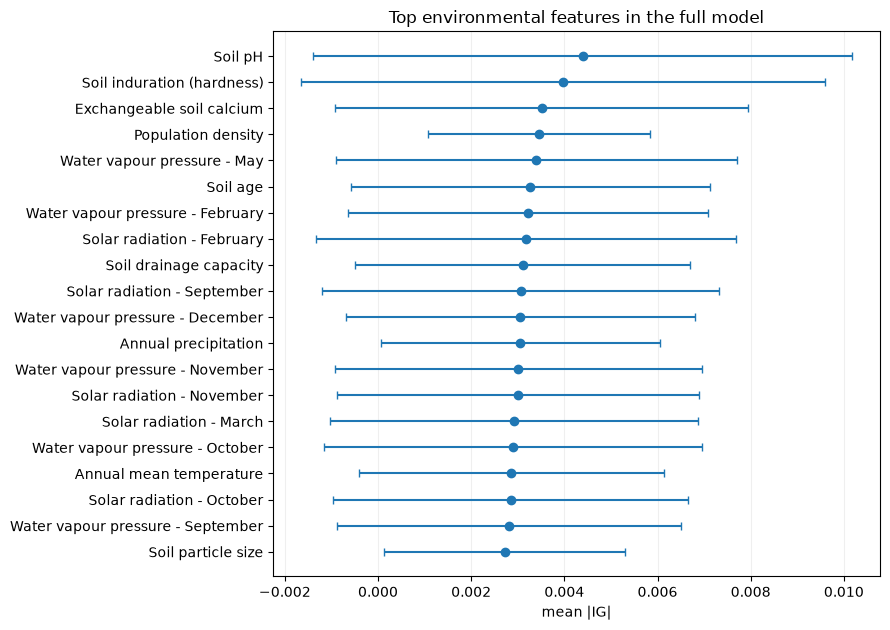

In [10]:
full_env=spatial_seed_feature.query("configuration_id == 'full' and input_group == 'Environment'").copy()
feature_seed=full_env.groupby(['seed','feature'],as_index=False)['mean_abs_ig'].mean()
env_feature_summary=summarise_seed_values(feature_seed,'mean_abs_ig',['feature']).sort_values('mean',ascending=False)
horizontal_ci_plot(env_feature_summary.head(TOP_N_FEATURES),'feature','Top environmental features in the full model','mean |IG|')

> ✅ Separating by traits, result are less uniform
**USARE**

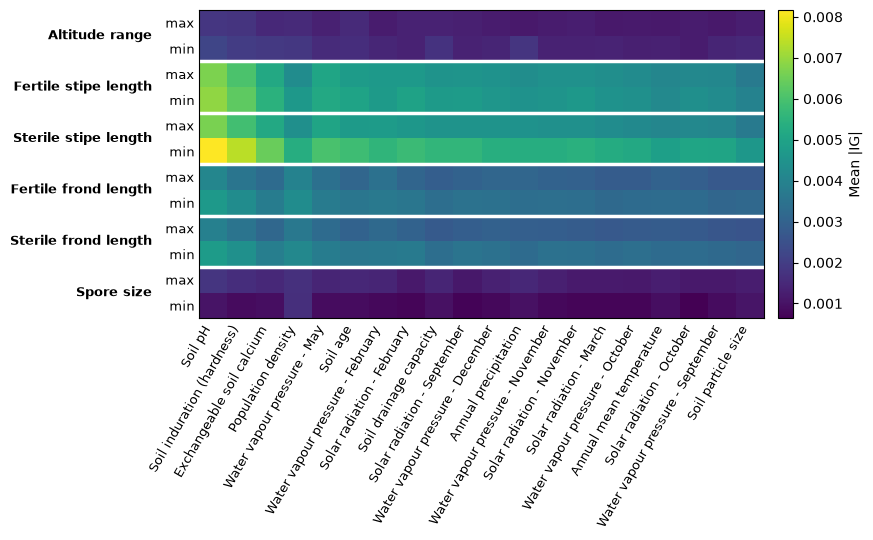

In [18]:
from matplotlib.transforms import ScaledTranslation

env_target_summary = summarise_seed_values(full_env, 'mean_abs_ig', 
                                           ['target_trait', 'variable', 'feature']
                                        )

top_features = env_feature_summary.head(TOP_N_FEATURES)['feature'].tolist()

hm = (
    env_target_summary[
        env_target_summary['feature'].isin(top_features)
    ]
    .assign(
        target=lambda d: d['target_trait'].astype(str) + ' · ' + d['variable'].astype(str)
    )
    .pivot(
        index='target', columns='feature', values='mean'
    )
)

# Keep features ordered by their global mean attribution
feature_order = [
    f for f in top_features
    if f in hm.columns
]
hm = hm[feature_order]

# Optional: use a biologically meaningful target order
# target_order = [ 
#     'Alt · max', 'Alt · min', 
#     'Spore · max', 'Spore · min', 
#     'FertileFrond · max', 'FertileFrond · min', 
#     'SterileFrond · max', 'SterileFrond · min', 
#     'Ferstipe · max', 'Ferstipe · min', 
#     'SterileStipe · max', 'SterileStipe · min',
#     ]
target_order = [f"{t} · {b}" for t in TARGET_ORDER for b in ['max', 'min'] if f"{t} · {b}" in hm.index]
hm = hm.reindex([x for x in target_order if x in hm.index])

# Split "Trait · bound" into the two y-axis levels
row_trait = [t.split(' · ')[0] for t in hm.index]
row_bound = [t.split(' · ')[1] for t in hm.index]


fig, ax = plt.subplots(
    figsize=(max(9, 0.45 * hm.shape[1]), 5.5)
)

im = ax.imshow(
    hm.to_numpy(dtype=float),
    aspect='auto',
    interpolation='nearest',
    cmap='viridis'
)

ax.set_xticks(np.arange(hm.shape[1]))
ax.set_xticklabels(hm.columns,rotation=60,ha='right')

# Inner y level: min / max
ax.set_yticks(np.arange(hm.shape[0]))
ax.set_yticklabels(row_bound)
# ax.set_xlabel('Environmental feature')
# ax.set_ylabel('Target trait')

# Outer y level: trait name (bold, centred on its min/max pair)
# + white separators between traits
label_trans = ax.get_yaxis_transform() + ScaledTranslation(
    -34 / 72, 0, fig.dpi_scale_trans
)
start = 0
for i in range(1, len(row_trait) + 1):
    if i == len(row_trait) or row_trait[i] != row_trait[start]:
        ax.text(
            0, (start + i - 1) / 2, pretty_trait_map.get(row_trait[start], "ND"),
            transform=label_trans, ha='right', va='center',
            fontsize=9, fontweight='bold'
        )
        if i < len(row_trait):
            ax.axhline(i - 0.5, color='white', linewidth=2.5)
        start = i

cbar = fig.colorbar(im, ax=ax, pad=0.02)
cbar.set_label(r'Mean $|\mathrm{IG}|$')

# No panel title: let the caption carry the explanation
ax.tick_params(axis='both', which='major', labelsize=9, length=0)

fig.savefig(PROJECT_ROOT / 'figures/env_feature_target_heatmap.pdf', dpi=300, bbox_inches='tight')
plt.tight_layout()
plt.show()

# Analysis B. Environmental domains

Features are heuristically grouped into Climate, Soil, Elevation, Human influence, and Other. Shares are calculated within each seed relative to the environmental total and then averaged across seeds.

> **TODO:** Verificare righe uguali e riportare, togliendo human influence

In [19]:
from matplotlib.lines import Line2D

domain_map = pd.DataFrame.from_dict(ENV_METADATA, orient='index')[['canonical', 'domain']].reset_index(drop=True).set_index('canonical').domain.to_dict()
d=full_env.copy()
d['domain']=d['feature'].map(lambda f: domain_map.get(f, 'Unknown'))

group_cols = ["seed", "target_trait", "variable", "domain"]

# Mean |IG| per feature within each domain.
domain_mean = d.groupby(group_cols,as_index=False).mean_abs_ig.mean().rename(columns={"mean_abs_ig": "domain_mean_abs_ig"})

# Total |IG| assigned to each domain.
domain_sum = d.groupby(group_cols, as_index=False).mean_abs_ig.sum().rename(columns={"mean_abs_ig": "domain_abs_ig"})


# Total environmental attribution for the corresponding prediction target.
environment_total = (
    domain_sum
    .groupby(["seed", "target_trait", "variable"], as_index=False)["domain_abs_ig"]
    .sum()
    .rename(columns={"domain_abs_ig": "environment_abs_ig"})
)

domain_sum = domain_sum.merge(
    environment_total,
    on=["seed", "target_trait", "variable"],
    how="left"
)

domain_sum["domain_share"] = (
    domain_sum["domain_abs_ig"]
    / domain_sum["environment_abs_ig"].replace(0, np.nan)
)

# Combine both quantities before summarising over seeds.
domain_values = domain_mean.merge(
    domain_sum[
        ["seed", "target_trait", "variable", "domain", "domain_share"]
    ],
    on=group_cols,
    how="inner"
)


# ---------------------------------------------------------------------
# 2. Summarise across benchmark seeds
# ---------------------------------------------------------------------

mean_summary = summarise_seed_values(
    domain_values,
    "domain_mean_abs_ig",
    ["target_trait", "variable", "domain"]
).rename(columns={"mean": "mean_abs_ig"})

share_summary = summarise_seed_values(
    domain_values,
    "domain_share",
    ["target_trait", "variable", "domain"]
).rename(columns={"mean": "share"})

plot_df = mean_summary[
    ["target_trait", "variable", "domain", "mean_abs_ig"]
].merge(
    share_summary[
        ["target_trait", "variable", "domain", "share"]
    ],
    on=["target_trait", "variable", "domain"],
    how="inner"
)

plot_df["target"] = (
    plot_df["target_trait"].astype(str)
    + " · "
    + plot_df["variable"].astype(str)
)


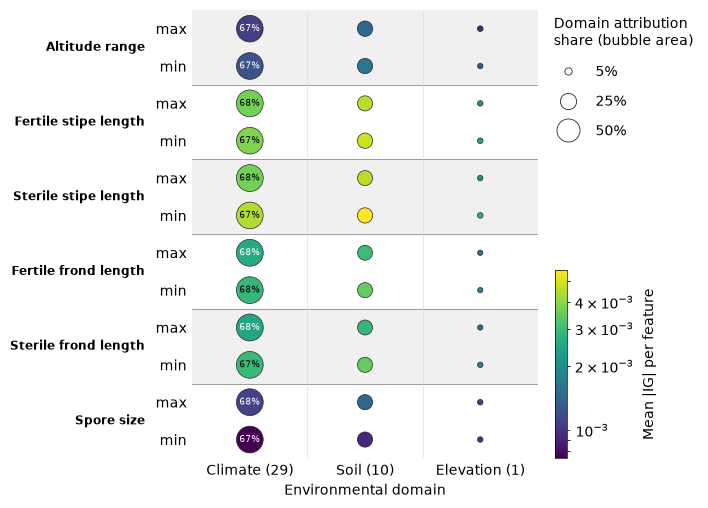

In [24]:
"""
Bubble matrix: domain attribution share (area) x mean absolute attribution
per feature (colour), for each predicted trait.

Expected columns in `plot_df`:
    target_trait : str   e.g. "Alt", "Spore", ...
    variable     : str   "min" | "max"
    domain       : str   e.g. "Climate", "Soil", ...
    mean_abs_ig  : float mean |IG| per feature within the domain
    share        : float fraction of total attribution carried by the domain
"""
import numpy as np
import pandas as pd
from matplotlib.colors import LogNorm, Normalize, PowerNorm
from matplotlib.lines import Line2D
from matplotlib.transforms import ScaledTranslation

# ---------------------------------------------------------------------
# Journal-style defaults
# ---------------------------------------------------------------------
# mpl.rcParams.update({
#     "font.size": 8,
#     "axes.labelsize": 9,
#     "axes.titlesize": 9,
#     "xtick.labelsize": 8,
#     "ytick.labelsize": 8,
#     "legend.fontsize": 8,
#     "legend.title_fontsize": 8,
#     "axes.linewidth": 0.6,
#     "pdf.fonttype": 42,   # editable text in vector output
#     "svg.fonttype": "none",
# })

BOUND_ORDER = ["max", "min"]
DOMAIN_ORDER = ["Climate", "Soil", "Elevation"]

norm_mode="log"         # "log" | "linear" | "power"
max_area=550           # marker area (pt^2) for share = 1.0
share_levels=(0.05, 0.25, 0.50)
annotate_min_share=0.30  # print % inside bubbles above this share
figwidth=7.2

# ---- keep only requested categories, build a complete grid ----------
domains_counts = pd.DataFrame(ENV_METADATA).T.domain.value_counts()
traits = [t for t in TARGET_ORDER if t in plot_df["target_trait"].unique()]
bounds = [b for b in BOUND_ORDER if b in plot_df["variable"].unique()]
domains = [d for d in DOMAIN_ORDER if d in plot_df["domain"].unique()]

rows = [(t, b) for t in traits for b in bounds]
row_idx = {r: i for i, r in enumerate(rows)}
col_idx = {d: i for i, d in enumerate(domains)}

p = plot_df.copy()
p["x"] = p["domain"].map(col_idx)
p["y"] = [row_idx.get((t, b)) for t, b in zip(p["target_trait"], p["variable"])]
p = p.dropna(subset=["x", "y"])

# ---- colour normalisation (attributions are often heavy-tailed) -----
vals = p["mean_abs_ig"]
if norm_mode == "log" and (vals > 0).all():
    norm = LogNorm(vmin=vals.min(), vmax=vals.max())
elif norm_mode == "power":
    norm = PowerNorm(gamma=0.5, vmin=vals.min(), vmax=vals.max())
else:
    norm = Normalize(vmin=vals.min(), vmax=vals.max())
cmap = plt.get_cmap('viridis')

# ---- bubble area strictly proportional to share ---------------------
# (no offset: an offset would break area <-> share proportionality)
areas = p["share"].clip(0, 1) * max_area

n_rows, n_cols = len(rows), len(domains)
fig_h = 0.34 * n_rows + 1.1
fig, ax = plt.subplots(figsize=(figwidth, fig_h))
fig.subplots_adjust(left=0.22, right=0.76, top=0.97, bottom=0.14)

# ---- background: alternate shading per trait, separators ------------
nb = len(bounds)
for k in range(len(traits)):
    lo, hi = k * nb - 0.5, (k + 1) * nb - 0.5
    if k % 2 == 0:
        ax.axhspan(lo, hi, color="0.94", zorder=0, lw=0)
    if k > 0:
        ax.axhline(lo, color="0.55", lw=0.6, zorder=1)
for x in np.arange(0.5, n_cols - 0.5, 1):
    ax.axvline(x, color="0.85", lw=0.4, zorder=1)

# ---- bubbles ---------------------------------------------------------
sc = ax.scatter(
    p["x"], p["y"], s=areas, c=vals, cmap=cmap, norm=norm,
    edgecolors="0.15", linewidths=0.5, zorder=3,
)

# ---- in-bubble percentages for the dominant domains ------------------
for _, r in p[p["share"] >= annotate_min_share].iterrows():
    rgba = cmap(norm(r["mean_abs_ig"]))
    lum = 0.299 * rgba[0] + 0.587 * rgba[1] + 0.114 * rgba[2]
    ax.text(r["x"], r["y"], f"{r['share']:.0%}", ha="center", va="center",
            fontsize=6.5, color="white" if lum < 0.5 else "black", zorder=4)

# ---- axes ------------------------------------------------------------
ax.set_xlim(-0.5, n_cols - 0.5)
ax.set_ylim(n_rows - 0.5, -0.5)               # first row on top
ax.set_xticks(range(n_cols), [f"{d} ({domains_counts[d]})" for d in domains])
ax.set_yticks(range(n_rows), [b for _, b in rows])
ax.tick_params(length=0, pad=4)
ax.set_xlabel("Environmental domain")
for s in ax.spines.values():
    s.set_visible(False)

# Trait names as a second, grouped y-level.
trans = ax.get_yaxis_transform() + ScaledTranslation(-34 / 72, 0, fig.dpi_scale_trans)
for k, t in enumerate(traits):
    yc = k * nb + (nb - 1) / 2
    t = pretty_trait_map.get(t, None)
    if t is None:
        raise ValueError(f"Trait '{t}' not found in pretty_trait_map")
    ax.text(0, yc, t, transform=trans, ha="right",
            va="center", fontsize=8.5, fontweight="bold")

# ---- colourbar (mean |attribution| per feature) ----------------------
cax = ax.inset_axes((1.05, 0.0, 0.035, 0.42))
cbar = fig.colorbar(sc, cax=cax)
cbar.set_label("Mean |IG| per feature", labelpad=6)
cbar.outline.set_linewidth(0.5)
cbar.ax.tick_params(width=0.5, length=2.5)

# ---- size legend (domain attribution share) --------------------------
handles = [
    Line2D([], [], ls="none", marker="o", markersize=np.sqrt(s * max_area),
            markerfacecolor="none", markeredgecolor="0.15",
            markeredgewidth=0.6, label=f"{s:.0%}")
    for s in share_levels
]
ax.legend(
    handles=handles, title="Domain attribution\nshare (bubble area)",
    loc="upper left", bbox_to_anchor=(1.03, 1.0), frameon=False,
    borderaxespad=0, labelspacing=1.1, handletextpad=1.0,
    alignment="left",
)
fig.savefig(PROJECT_ROOT / 'figures/env_domain_bubble_matrix.pdf', dpi=300, bbox_inches="tight")
plt.tight_layout()
plt.show()

## Recommended interpretation of the results

A pattern consistent with **no collapse of the environmental branch** is:

- an environmental share in the spatial branch that remains consistently above zero;
- multiple environmental features with consistent `mean |IG|` across seeds;
- an effective number of features substantially greater than 1;
- correlated environmental rankings between `Environment only` and `Full`;
- non-negligible top-k overlap;
- no general convergence of `Full - Environment only` to zero;
- different environmental domains associated with different targets;
- heterogeneity across species, indicating non-uniform use of environmental information;
- relatively stable signed-IG directions for the main features.

This evidence describes model behavior and attribution robustness. It does not demonstrate biological causality and does not require the environment to improve mean predictive error.